# UTS Data Mining - Klasifikasi Kualitas Anggur (Wine Quality)

**Nama:** Rida Tsaniya Putri Hamdani

**NIM:** 2404010005  

**Prodi:** Staterkom

**Mata Kuliah:** Data Mining

## Tujuan
Bikin model klasifikasi buat memprediksi **quality** anggur (skala 0-10) dari data kimiawinya. Model dilatih pakai `data_training.csv`, terus dipakai buat prediksi `data_testing.csv`.

## Alur Pengerjaan
1. Persiapan data
2. Pembersihan data (missing value, duplikat, scaling)
3. Pembuatan & evaluasi model
4. Prediksi data testing
5. Simpan hasil ke CSV (`id` dan `quality`)

In [23]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

kode diatas digunakan untuk menggolah data, membangun model dan mengevaluasi hasil.

In [24]:
df_train = pd.read_csv("data_training.csv") # Membaca dataset
df_test = pd.read_csv("data_testing.csv")

print("Ukuran data training:", df_train.shape) # Melihat ukuran dataset
print("Ukuran data testing:", df_test.shape)

display(df_train.head()) # Membaca dataset
display(df_test.head())

Ukuran data training: (857, 13)
Ukuran data testing: (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


Data training digunakan untuk mmbuat model atau pola analisisanya sedangkan untuk data testing nya untuk memprediksi kualitas anggurnya.

In [25]:
df_train.info() # Informasi data training

df_test.info() # Informasi data testing

display(df_train.describe(include="all").T) # Statistik deskriptif

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 857 entries, 0 to 856
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         857 non-null    float64
 1   volatile acidity      857 non-null    float64
 2   citric acid           857 non-null    float64
 3   residual sugar        857 non-null    float64
 4   chlorides             857 non-null    float64
 5   free sulfur dioxide   857 non-null    float64
 6   total sulfur dioxide  857 non-null    float64
 7   density               857 non-null    float64
 8   pH                    857 non-null    float64
 9   sulphates             857 non-null    float64
 10  alcohol               857 non-null    float64
 11  quality               857 non-null    int64  
 12  Id                    857 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 87.2 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286 entries, 0 to 285
Data c

,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
pH,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000


tahap ini untuk mengetahui tipe data dan statistik setiap variabel

In [26]:
# Mencari kolom target
target_col = next(
    (c for c in df_train.columns if c.lower() == "quality"),
    None
)

if target_col is None:
    raise ValueError("Kolom quality tidak ditemukan.")

# Mencari kolom ID
id_train_col = next(
    (c for c in df_train.columns if c.lower() == "id"),
    None
)

id_test_col = next(
    (c for c in df_test.columns if c.lower() == "id"),
    None
)

# Menyimpan ID data testing
if id_test_col is not None:
    id_testing = df_test[id_test_col].copy()
else:
    id_testing = None

# Memeriksa missing values
print("Missing value training:")
display(df_train.isnull().sum())

print("Missing value testing:")
display(df_test.isnull().sum())

# Memeriksa duplikat
print("Duplikat training:", df_train.duplicated().sum())
print("Duplikat testing:", df_test.duplicated().sum())

Missing value training:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Missing value testing:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Duplikat training: 0
Duplikat testing: 0


Pemeriksaan dilakukan untuk mengetahui missing values dan data duplikat.

In [27]:
# Menghapus data yang target quality-nya kosong
df_train = df_train.dropna(subset=[target_col]).copy()

# Memisahkan fitur dan target
y = df_train[target_col]

kolom_tidak_digunakan = [target_col]

if id_train_col is not None:
    kolom_tidak_digunakan.append(id_train_col)

X = df_train.drop(columns=kolom_tidak_digunakan)

# Memisahkan fitur testing
X_test = df_test.drop(
    columns=[id_test_col] if id_test_col is not None else []
)

# Memastikan kolom training dan testing sama
kolom_hilang = [
    c for c in X.columns if c not in X_test.columns
]

kolom_tambahan = [
    c for c in X_test.columns if c not in X.columns
]

if kolom_hilang:
    raise ValueError(
        f"Kolom tidak ditemukan di testing: {kolom_hilang}"
    )

if kolom_tambahan:
    print("Kolom tambahan tidak digunakan:", kolom_tambahan)
    X_test = X_test.drop(columns=kolom_tambahan)

X_test = X_test[X.columns]

print("Jumlah fitur:", X.shape[1])
print("Jumlah data training:", X.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah fitur: 11
Jumlah data training: 857
Jumlah data testing: 286


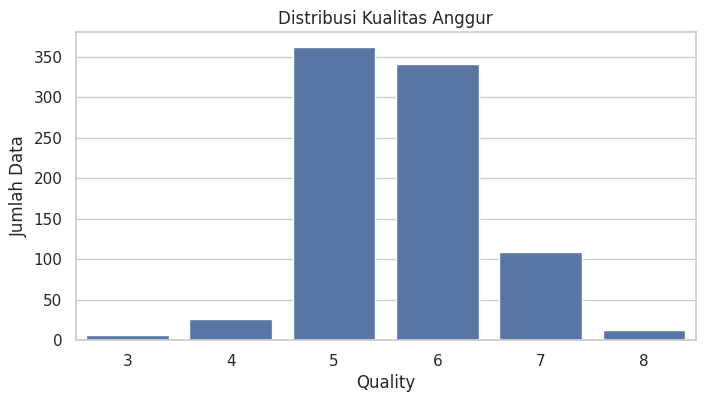

,count
quality,
3,6
4,26
5,362
6,341
7,109
8,13


In [28]:
# melihat distribusi kualitas anggur
plt.figure(figsize=(8, 4))

sns.countplot(
    data=df_train,
    x=target_col
)

plt.title("Distribusi Kualitas Anggur")
plt.xlabel("Quality")
plt.ylabel("Jumlah Data")

plt.show()

display(df_train[target_col].value_counts().sort_index())

EDA digunakan untuk melihat distribusi kualitas anggur.

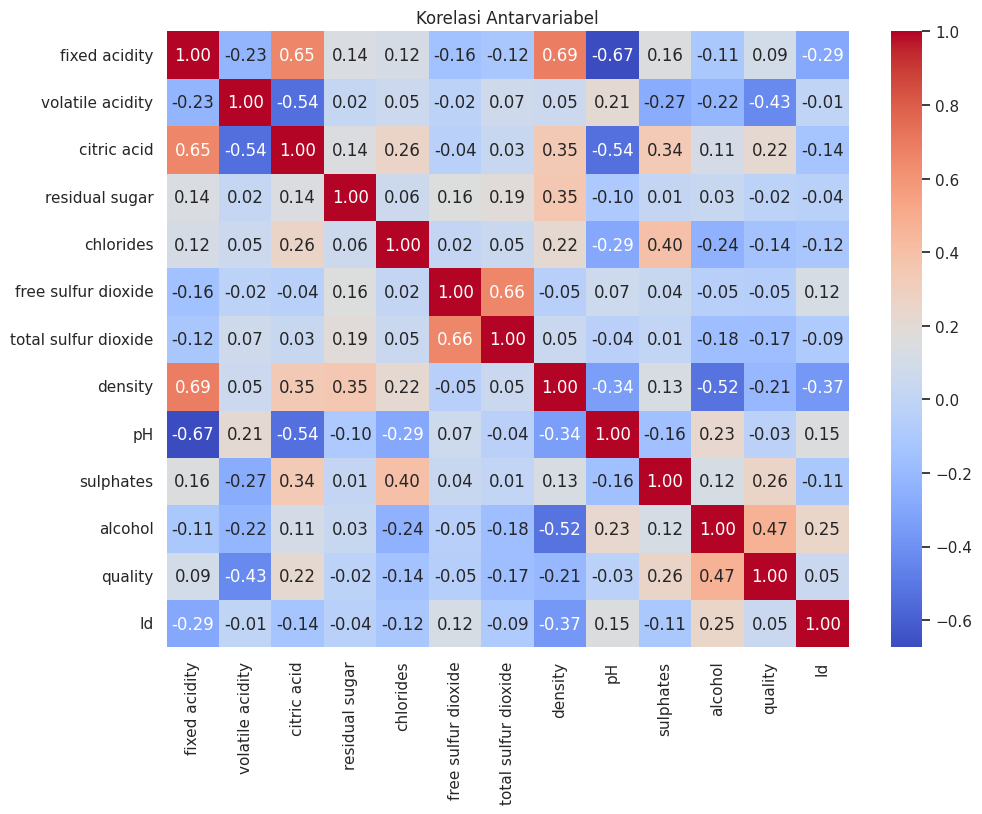

In [29]:
# melihat korelasi antarvariabel
data_numerik = df_train.select_dtypes(include=np.number)

plt.figure(figsize=(11, 8))

sns.heatmap(
    data_numerik.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Korelasi Antarvariabel")
plt.show()

syntax diatas digunakan untuk melihat korelasi antarvariabel.

In [30]:
# Memisahkan fitur numerik dan kategori
kolom_numerik = X.select_dtypes(
    include=np.number
).columns.tolist()

kolom_kategori = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Fitur numerik:", kolom_numerik)
print("Fitur kategori:", kolom_kategori)

Fitur numerik: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Fitur kategori: []


In [31]:
# melakukan preprocess dengan metode scaling
preprocess_scaling = ColumnTransformer([
    ("numerik", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), kolom_numerik),

    ("kategori", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), kolom_kategori)
])

In [32]:
# melakukan preprocess dengan metode tree
preprocess_pohon = ColumnTransformer([
    ("numerik",
     SimpleImputer(strategy="median"),
     kolom_numerik),

    ("kategori", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), kolom_kategori)
])

In [33]:
# Mengecek jumlah data pada setiap kelas
jumlah_minimum_kelas = y.value_counts().min()

if jumlah_minimum_kelas >= 2:
    stratifikasi = y
else:
    stratifikasi = None

# Membagi data
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratifikasi
)

print("Data latih:", X_train.shape)
print("Data validasi:", X_valid.shape)

Data latih: (685, 11)
Data validasi: (172, 11)


Data training dibagi menjadi 80% data latih dan 20% data validasi.

In [34]:
#pembuatan model klasidikasi yang tepat
models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocess_scaling),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "KNN": Pipeline([
        ("preprocess", preprocess_scaling),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Random Forest": Pipeline([
        ("preprocess", preprocess_pohon),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocess", preprocess_pohon),
        ("model", GradientBoostingClassifier(
            random_state=42
        ))
    ])
}

Empat algoritma digunakan untuk dibandingkan, yaitu Logistic Regression, KNN, Random Forest, dan Gradient Boosting.

In [35]:
hasil_model = []

for nama, model in models.items():

    # Melatih model
    model.fit(X_train, y_train)

    # Prediksi data validasi
    prediksi = model.predict(X_valid)

    # Menghitung evaluasi
    hasil_model.append({
        "Model": nama,

        "Accuracy": accuracy_score(
            y_valid, prediksi
        ),

        "F1-Score Macro": f1_score(
            y_valid,
            prediksi,
            average="macro",
            zero_division=0
        )
    })

# Membuat tabel perbandingan
tabel_model = pd.DataFrame(hasil_model)

tabel_model = tabel_model.sort_values(
    by="F1-Score Macro",
    ascending=False
).reset_index(drop=True)

display(tabel_model)

,Model,Accuracy,F1-Score Macro
0,Gradient Boosting,0.622093,0.407910
1,Random Forest,0.651163,0.367751
2,Logistic Regression,0.610465,0.285125
3,KNN,0.482558,0.248955


Keterangan: Hasil dari setiap algoritma dibandingkan menggunakan Accuracy dan F1-Score Macro. Model dengan F1-Score Macro tertinggi menjadi kandidat model terbaik.

In [36]:
# Menentukan jumlah fold
jumlah_fold = min(5, int(y.value_counts().min()))

if jumlah_fold >= 2:

    skf = StratifiedKFold(
        n_splits=jumlah_fold,
        shuffle=True,
        random_state=42
    )

    hasil_cv = []

    for nama, model in models.items():

        skor = cross_val_score(
            model,
            X,
            y,
            cv=skf,
            scoring="f1_macro",
            n_jobs=-1
        )

        hasil_cv.append({
            "Model": nama,
            "Rata-rata F1 CV": skor.mean(),
            "Standar Deviasi": skor.std()
        })

    tabel_cv = pd.DataFrame(hasil_cv)

    tabel_cv = tabel_cv.sort_values(
        by="Rata-rata F1 CV",
        ascending=False
    )

    display(tabel_cv)

else:
    print(
        "Cross-validation tidak dilakukan karena "
        "jumlah data pada salah satu kelas terlalu sedikit."
    )

,Model,Rata-rata F1 CV,Standar Deviasi
2,Random Forest,0.342664,0.043490
3,Gradient Boosting,0.338447,0.034597
0,Logistic Regression,0.273973,0.021553
1,KNN,0.263953,0.025881


Cross-validation dilakukan untuk mengetahui kestabilan performa model pada beberapa pembagian data.

In [37]:
# Memilih model terbaik
nama_model_terbaik = tabel_model.loc[0, "Model"]

model_terbaik = models[nama_model_terbaik]

print("Model terbaik:", nama_model_terbaik)

# Prediksi data validasi
prediksi_validasi = model_terbaik.predict(X_valid)

# Menampilkan hasil evaluasi
print("Accuracy:",
      round(accuracy_score(y_valid, prediksi_validasi), 4))

print("F1-Score Macro:",
      round(f1_score(
          y_valid,
          prediksi_validasi,
          average="macro",
          zero_division=0
      ), 4))

print("\nClassification Report:")

print(classification_report(
    y_valid,
    prediksi_validasi,
    zero_division=0
))

Model terbaik: Gradient Boosting
Accuracy: 0.6221
F1-Score Macro: 0.4079

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.33      0.20      0.25         5
           5       0.69      0.74      0.72        73
           6       0.58      0.62      0.60        68
           7       0.60      0.41      0.49        22
           8       0.50      0.33      0.40         3

    accuracy                           0.62       172
   macro avg       0.45      0.38      0.41       172
weighted avg       0.62      0.62      0.62       172



Model terbaik dipilih berdasarkan hasil F1-Score Macro pada data validasi. dan dari hasil pemilhan model terbaik adalah gradient boosting

<Figure size 800x600 with 0 Axes>

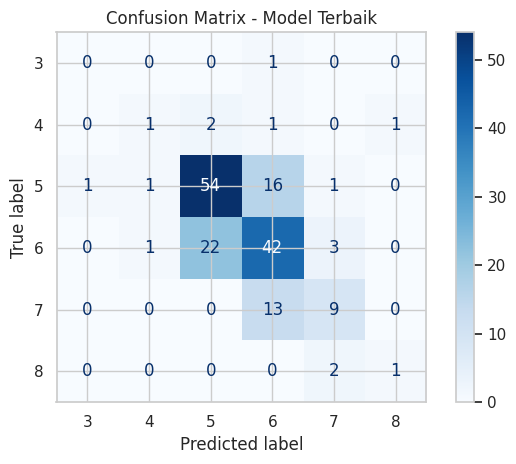

In [38]:
plt.figure(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    prediksi_validasi,
    cmap="Blues"
)

plt.title("Confusion Matrix - Model Terbaik")
plt.tight_layout()
plt.show()

Classification report menunjukkan nilai precision, recall, dan F1-score setiap kelas. Confusion matrix menunjukkan jumlah prediksi yang benar dan salah.

,0
numerik__alcohol,0.214375
numerik__volatile acidity,0.142240
numerik__sulphates,0.130488
numerik__total sulfur dioxide,0.099231
numerik__fixed acidity,0.082359
numerik__density,0.068070
numerik__chlorides,0.062030
numerik__pH,0.054876
numerik__citric acid,0.054354
numerik__residual sugar,0.046470


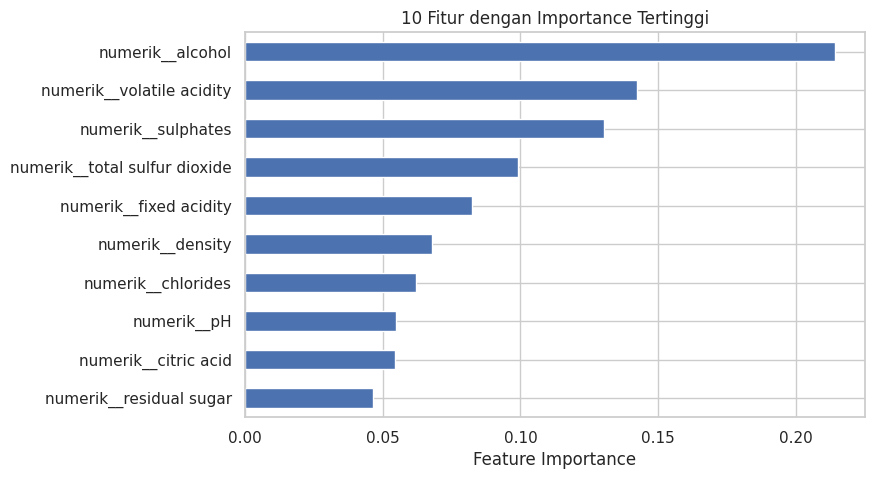

In [39]:
model_akhir_di_pipeline = model_terbaik.named_steps["model"]

if hasattr(model_akhir_di_pipeline, "feature_importances_"):

    nama_fitur = (
        model_terbaik
        .named_steps["preprocess"]
        .get_feature_names_out()
    )

    nilai_penting = model_akhir_di_pipeline.feature_importances_

    importance = pd.Series(
        nilai_penting,
        index=nama_fitur
    ).sort_values(ascending=False)

    display(importance.head(10))

    importance.head(10).sort_values().plot(
        kind="barh",
        figsize=(8, 5)
    )

    plt.title("10 Fitur dengan Importance Tertinggi")
    plt.xlabel("Feature Importance")
    plt.show()

else:
    print(
        "Feature importance tidak tersedia "
        "untuk model yang terpilih."
    )

Grafik menunjukkan fitur yang paling banyak digunakan atau berkontribusi dalam proses pengambilan keputusan model. Nilai ini bukan berarti fitur tersebut menyebabkan perubahan kualitas anggur.

In [40]:
# Melatih ulang model menggunakan seluruh data training
model_terbaik.fit(X, y)

# Menyimpan model
joblib.dump(
    model_terbaik,
    "model_wine_quality.pkl"
)

print("Model berhasil disimpan.")

Model berhasil disimpan.


Setelah model terbaik ditemukan, model dilatih ulang menggunakan seluruh data training.

In [41]:
# Melakukan prediksi
prediksi_testing = model_terbaik.predict(X_test)

print("Jumlah data testing:", len(X_test))
print("Jumlah hasil prediksi:", len(prediksi_testing))

# Menampilkan 10 hasil pertama
display(pd.DataFrame({
    "Quality": prediksi_testing
}).head(10))

Jumlah data testing: 286
Jumlah hasil prediksi: 286


,Quality
0,6
1,6
2,5
3,5
4,5
5,6
6,5
7,5
8,6
9,5


Hasil prediksi merupakan nilai quality yang diperkirakan oleh model berdasarkan fitur kimiawi anggur.

In [42]:
# Mengambil ID dari data testing
if id_testing is not None:

    ids = id_testing.reset_index(drop=True)

# Jika ID tidak ada, gunakan ID dari template dosen
elif os.path.exists("hasilprediksi_3digitNIMterakhir.csv"):

    template = pd.read_csv(
        "hasilprediksi_3digitNIMterakhir.csv"
    )

    kolom_id_template = next(
        (c for c in template.columns if c.lower() == "id"),
        None
    )

    if kolom_id_template is None:
        raise ValueError("Kolom ID tidak ditemukan di template.")

    if len(template) != len(prediksi_testing):
        raise ValueError("Jumlah baris template tidak sesuai.")

    ids = template[kolom_id_template].reset_index(drop=True)

else:
    raise ValueError(
        "ID tidak ditemukan. Upload data testing yang memiliki "
        "ID atau template resmi dosen."
    )

# Membuat dataframe hasil prediksi
hasil_prediksi = pd.DataFrame({
    "Id": ids,
    "Quality": prediksi_testing
})

# Memastikan hanya dua kolom
hasil_prediksi = hasil_prediksi[["Id", "Quality"]]

display(hasil_prediksi.head())

# Menyimpan hasil prediksi
nama_file = "hasilprediksi_XXX.csv"

hasil_prediksi.to_csv(
    nama_file,
    index=False
)

print("File berhasil disimpan:", nama_file)

,Id,Quality
0,222,6
1,1514,6
2,417,5
3,754,5
4,516,5


File berhasil disimpan: hasilprediksi_XXX.csv


In [43]:
# Membaca kembali data testing
data_testing = pd.read_csv("data_testing.csv")

# Mengecek data
display(data_testing.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Id
0,6.8,0.61,0.04,1.5,0.057,5.0,10.0,0.99525,3.42,0.60,9.500000,222
1,6.9,0.84,0.21,4.1,0.074,16.0,65.0,0.99842,3.53,0.72,9.233333,1514
2,7.0,0.58,0.12,1.9,0.091,34.0,124.0,0.99560,3.44,0.48,10.500000,417
3,7.8,0.48,0.68,1.7,0.415,14.0,32.0,0.99656,3.09,1.06,9.100000,754
4,12.5,0.60,0.49,4.3,0.100,5.0,14.0,1.00100,3.25,0.74,11.900000,516


In [44]:
# Membuat hasil prediksi dengan dua kolom saja
hasil_prediksi = pd.DataFrame({
    "Id": data_testing["Id"],
    "Quality": prediksi_testing
})

# Menyimpan hasil prediksi ke CSV
hasil_prediksi.to_csv(
    "hasilprediksi_005.csv",
    index=False
)

# Menampilkan hasil prediksi
display(hasil_prediksi.head())

print("Hasil prediksi berhasil disimpan!")

,Id,Quality
0,222,6
1,1514,6
2,417,5
3,754,5
4,516,5


Hasil prediksi berhasil disimpan!
